In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra
using JLD2

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.0011477876073095398 - 0.003988660151171481im 0.0009565353006530629 - 0.00016643583320137748im … -0.0020251701119632175 + 0.0013572182414077903im 0.0018619455772395305 - 0.0025928813713085807im; -0.0034140374352435504 + 0.0023178371105131972im 0.0015926130600213014 + 0.00380386004735736im … -0.003961352322458235 + 0.0010724613052039106im 0.00204992871638014 - 0.0004853697621026681im; -0.001361085839480976 - 0.0035551167521326358im -0.003229266219558758 - 0.003298608219105357im … -0.0008271982767318332 - 0.0013569689287634406im 0.002034118485443556 - 0.0003306123283787003im;;; -0.0023469709765784907 - 0.004310513456922338im 0.0009616673650847515 - 0.00010952867044130383im … 0.0021139062396376474 + 0.0034777889727650112im -0.0008890262003798601 - 0.0025147031349551084im; -0.0003837076309134191 - 0.0003428445213982299im 0.0009374796189413421 - 0.0010303245581861297im … 0.0009594799931608916 - 9.119133252064855e-

In [3]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-1.4015531856217429e-5 - 3.2949636589837164e-6im -1.7031487901466356e-5 + 2.744255672570553e-7im … -3.0112364241805794e-6 + 6.363086910095043e-6im -1.8028318059537627e-6 - 1.0281981882186828e-5im; 8.230487825914008e-7 + 2.470486258687612e-6im -7.389358467608872e-7 + 1.7919829975464426e-6im … 8.40766980060933e-6 + 7.719623254109248e-6im -5.331081412192807e-6 + 5.410241109661858e-6im; -2.448659086371969e-6 - 3.6860741517429158e-6im -3.840291880485639e-6 - 3.955424937294532e-6im … 5.441216404033308e-6 - 1.3299556759942453e-5im 4.403201744235491e-6 - 2.1976691729192757e-6im;;; 3.6093042321532774e-6 - 2.399578055420637e-6im -8.79599880206636e-7 + 1.8239908912161358e-6im … -2.736486467665664e-6 - 6.10378377972466e-6im -1.1544041505557819e-7 + 1.3791381915884617e-6im; -3.397200842878451e-6 - 7.008193187895164e-6im -2.572680890438035e-6 - 9.467158468429687e-6im … -1.418500957902867e-6 + 1.3861701544046138e-6im 2.976971

In [4]:
P=Onestep()
hop=Hopping_operator(U,P)
W=Generate_weight(hop)
W1=deepcopy(W)

9-element Vector{Spin_matrix}:
 [-0.6870833954001669 + 0.0im 1.8964735299019324 + 0.0im -1.6463009211272601 + 0.0im -0.9970019381906609 + 0.0im; 0.059681639841259404 + 0.0im 1.421736312355609 + 0.0im -0.4204459634240954 + 0.0im -2.2440281691239012 + 0.0im; 2.2373870213104072 + 0.0im -0.45533143741716625 + 0.0im 0.027820303271929588 + 0.0im -0.41288940309176075 + 0.0im; -0.7599974196895432 + 0.0im 0.3017980143767053 + 0.0im 0.9027539843753162 + 0.0im -0.7108932317153879 + 0.0im]
 [0.2337085354103764 + 0.0im -1.141089287421875 + 0.0im 1.6316706201208095 + 0.0im -0.1890665049335752 + 0.0im; -1.6191032234991223 + 0.0im 0.5335478911155306 + 0.0im -3.9013334770364563 + 0.0im -1.119158427581062 + 0.0im; -0.4444684464151841 + 0.0im 1.2244602756312681 + 0.0im -0.06806116424413006 + 0.0im 0.8200332153111013 + 0.0im; 0.8078920084481324 + 0.0im -0.35748701133714383 + 0.0im 0.41670944230414236 + 0.0im -0.345437473915727 + 0.0im]
 [0.503402110224559 + 0.0im -0.4143813417668911 + 0.0im -0.84021881853

In [5]:
layer=CPTC_Layer(hop,W)
layer1=PTC_Layer(hop,W1)

PTC_Layer(Spin_matrix[[-0.6870833954001669 + 0.0im 1.8964735299019324 + 0.0im -1.6463009211272601 + 0.0im -0.9970019381906609 + 0.0im; 0.059681639841259404 + 0.0im 1.421736312355609 + 0.0im -0.4204459634240954 + 0.0im -2.2440281691239012 + 0.0im; 2.2373870213104072 + 0.0im -0.45533143741716625 + 0.0im 0.027820303271929588 + 0.0im -0.41288940309176075 + 0.0im; -0.7599974196895432 + 0.0im 0.3017980143767053 + 0.0im 0.9027539843753162 + 0.0im -0.7108932317153879 + 0.0im], [0.2337085354103764 + 0.0im -1.141089287421875 + 0.0im 1.6316706201208095 + 0.0im -0.1890665049335752 + 0.0im; -1.6191032234991223 + 0.0im 0.5335478911155306 + 0.0im -3.9013334770364563 + 0.0im -1.119158427581062 + 0.0im; -0.4444684464151841 + 0.0im 1.2244602756312681 + 0.0im -0.06806116424413006 + 0.0im 0.8200332153111013 + 0.0im; 0.8078920084481324 + 0.0im -0.35748701133714383 + 0.0im 0.41670944230414236 + 0.0im -0.345437473915727 + 0.0im], [0.503402110224559 + 0.0im -0.4143813417668911 + 0.0im -0.8402188185323025 + 0.

In [6]:
norm2(layer(x))

1.6050345368144028e7 + 0.0im

In [7]:
opt=Adam()
opt.α=0.05

0.05

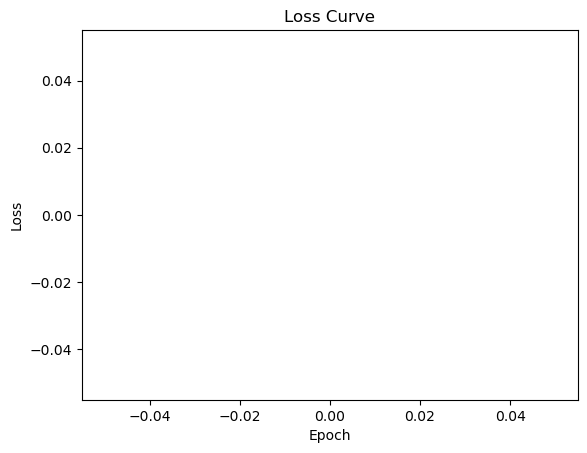

Epoch: 1, Loss: 41.649799112321816 + 0.0im
Epoch: 2, Loss: 38.51992576770078 + 0.0im
Epoch: 3, Loss: 35.55987755384271 + 0.0im
Epoch: 4, Loss: 32.996055914952464 + 0.0im
Epoch: 5, Loss: 30.781784208631024 + 0.0im
Epoch: 6, Loss: 28.33995397757997 + 0.0im
Epoch: 7, Loss: 26.045268464072535 + 0.0im
Epoch: 8, Loss: 24.064118980766562 + 0.0im
Epoch: 9, Loss: 22.25856925963897 + 0.0im
Epoch: 10, Loss: 20.450382312463706 + 0.0im
Epoch: 11, Loss: 19.053093512982457 + 0.0im
Epoch: 12, Loss: 17.440927754080263 + 0.0im
Epoch: 13, Loss: 16.005109272401018 + 0.0im
Epoch: 14, Loss: 14.937030433105313 + 0.0im
Epoch: 15, Loss: 13.80392802419807 + 0.0im
Epoch: 16, Loss: 12.647373109557941 + 0.0im
Epoch: 17, Loss: 11.7180857203905 + 0.0im
Epoch: 18, Loss: 10.895496123119521 + 0.0im
Epoch: 19, Loss: 10.036030895577975 + 0.0im
Epoch: 20, Loss: 9.317775092427576 + 0.0im
Epoch: 21, Loss: 8.640504049448285 + 0.0im
Epoch: 22, Loss: 7.9725377799574035 + 0.0im
Epoch: 23, Loss: 7.365288724589447 + 0.0im
Epoch: 

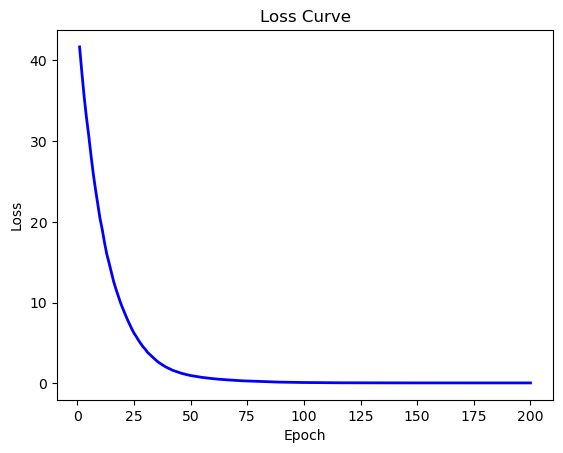

In [8]:
train(opt,[layer1],x,t,D,epochs=200)


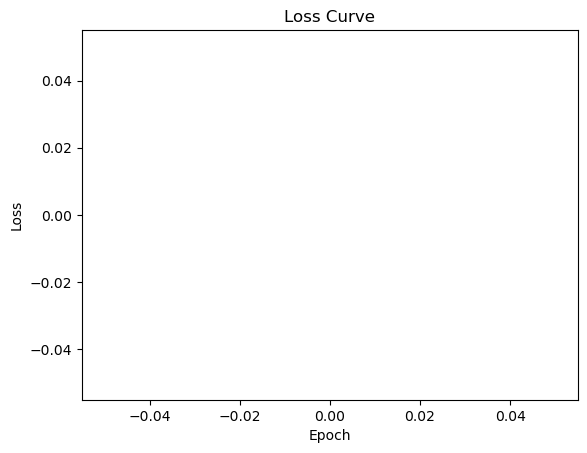

Epoch: 1, Loss: 169.05191392106218 + 0.0im
Epoch: 2, Loss: 151.52022547045422 + 0.0im
Epoch: 3, Loss: 132.2968356527733 + 0.0im
Epoch: 4, Loss: 112.09127146752745 + 0.0im
Epoch: 5, Loss: 93.02679745107328 + 0.0im
Epoch: 6, Loss: 75.93236061818185 + 0.0im
Epoch: 7, Loss: 61.14582615378274 + 0.0im
Epoch: 8, Loss: 49.84420767923311 + 0.0im
Epoch: 9, Loss: 40.51657536725595 + 0.0im
Epoch: 10, Loss: 33.20262849777877 + 0.0im
Epoch: 11, Loss: 27.439608637023092 + 0.0im
Epoch: 12, Loss: 22.802699363157064 + 0.0im
Epoch: 13, Loss: 19.345300744553796 + 0.0im
Epoch: 14, Loss: 16.601957384889868 + 0.0im
Epoch: 15, Loss: 14.200559323618025 + 0.0im
Epoch: 16, Loss: 12.465888009790623 + 0.0im
Epoch: 17, Loss: 11.091779191659592 + 0.0im
Epoch: 18, Loss: 9.941345660300625 + 0.0im
Epoch: 19, Loss: 9.195380391386546 + 0.0im
Epoch: 20, Loss: 8.563923000742735 + 0.0im
Epoch: 21, Loss: 8.120428963850841 + 0.0im
Epoch: 22, Loss: 7.7270801454108495 + 0.0im
Epoch: 23, Loss: 7.455843372013005 + 0.0im
Epoch: 24

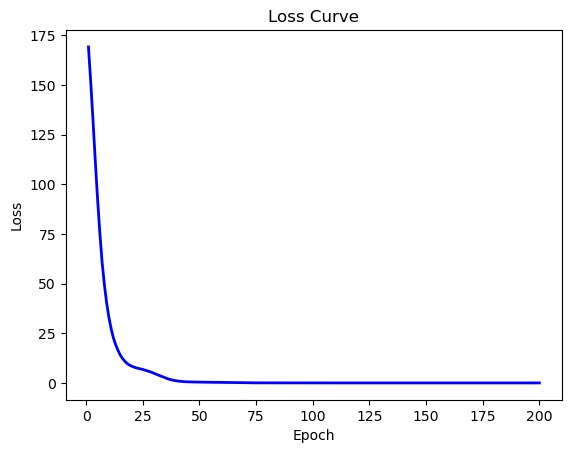

In [9]:
train(opt,[layer],x,t,D,epochs=200)

In [10]:
Lossfunction(layer1(input),target)

4.106900881039709e-7 + 0.0im

In [11]:
b = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
u = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(b)
gauss_distribution_fermion!(u)
u=deepcopy(b)

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-0.01672255472014605 - 0.6428589412598228im -0.47164146796760487 - 0.02602164330170179im … -0.34856500807148283 - 0.8703055994719867im 0.3297661886367418 - 0.3805806733463331im; -0.013721569658294875 + 1.0235439567223024im -1.464517662657271 + 0.5690194307962778im … -0.02457912905903176 + 0.9149284072283919im -0.22997839986146767 + 0.7608988801402247im; 0.208282204616618 + 0.4269547927488019im -0.6107040593400239 + 0.2582716639820014im … -0.18501530407895733 - 0.3206643935513689im -0.058297803230272685 - 0.466252218096243im;;; 1.4912519646880082 + 0.2157507004388985im 1.0755194077829031 - 1.0632698645741212im … -0.13198984060597538 - 0.167443942957156im 0.7482659458931943 - 0.2726527569526844im; -0.6086434970564488 + 0.25992054873574594im -1.5174406764616306 + 1.016696180518724im … -0.6449299317135085 - 0.8423562481807798im -0.11024849047237753 + 0.20573286738178553im; 0.5716691179058432 + 0.4050820324103685im 

In [12]:
@save "PTC_weight.jld2" W  

In [13]:
source=Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
source[1,1,1,1,1,1]=1


1

In [14]:
gmres(b,D,source)

Converged at 2-9-th step. eps: 6.305486192077413e-11


In [15]:
M=[layer1]

1-element Vector{PTC_Layer}:
 PTC_Layer(Spin_matrix[[-0.08850861374677892 + 0.0005572317824325071im 0.00039147520868481413 - 0.000616761036318789im -0.0003155269018050224 - 0.0020762559350601902im -0.0003678506576843615 + 0.0009804031152345816im; -0.0004264687576684204 + 0.0018081012934148479im -0.0884057277309765 + 0.0021852511926775935im -0.0012262296605961632 + 0.00029660552654154173im 8.93874442594744e-5 - 0.000996529766045815im; 0.0002902740732885699 - 0.0022476728229504357im -0.0007791869377600049 + 0.0011664709343478738im -0.08873982337027417 + 0.00043299472545013515im 0.0005791206395958567 + 0.0007962861852319838im; 0.000283896241204514 + 0.002060093999454427im -0.0018549217423662542 + 0.0011866061640347563im 0.00023678478026220248 - 0.00014933790072280833im -0.08761959227963145 + 0.000627401066755589im], [0.08943949220132591 - 0.001364000344863404im 0.0005216439382708495 - 0.0011718757004002683im 8.855951545183451e-5 - 0.00035608148740931024im 0.002232379733605193 - 0.10544550